# Model ML

In [1]:
import pandas as pd

In [2]:
pr = pd.read_csv('casebooks/data/problems.csv')

In [3]:
pr.drop(['read_books','recomendations','recom_ratings'],axis=1,inplace=True)

In [4]:
df = pd.read_csv('D:\Escritorio\casebooks_SBC\interactions.csv') 
#aqui es directori adient ja que no hi cap a github

In [5]:
df.drop(['is_read','is_reviewed'],axis=1,inplace=True)

In [6]:
df_merged = pr.merge(df[['user_id', 'book_id', 'rating']], on='user_id', how='inner')

In [7]:
df_merged

,user_id,Fantasy,Fiction,Mystery,Poetry,History,Romance,Non-fiction,Children,Young-adult,Comics,avg_pages,count,avg_rating,book_id,rating
0,70551,0.093,0.251,0.094,0.013,0.118,0.040,0.259,0.077,0.031,0.025,244.125,42,3.5,3884,4
1,70551,0.093,0.251,0.094,0.013,0.118,0.040,0.259,0.077,0.031,0.025,244.125,42,3.5,50876,5
2,70551,0.093,0.251,0.094,0.013,0.118,0.040,0.259,0.077,0.031,0.025,244.125,42,3.5,75731,4
3,70551,0.093,0.251,0.094,0.013,0.118,0.040,0.259,0.077,0.031,0.025,244.125,42,3.5,12948,4
4,70551,0.093,0.251,0.094,0.013,0.118,0.040,0.259,0.077,0.031,0.025,244.125,42,3.5,7011,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74411,618484,0.155,0.340,0.102,0.020,0.089,0.023,0.174,0.021,0.030,0.045,303.500,25,3.0,7955,3
74412,618484,0.155,0.340,0.102,0.020,0.089,0.023,0.174,0.021,0.030,0.045,303.500,25,3.0,1473,3
74413,618484,0.155,0.340,0.102,0.020,0.089,0.023,0.174,0.021,0.030,0.045,303.500,25,3.0,461,2
74414,618484,0.155,0.340,0.102,0.020,0.089,0.023,0.174,0.021,0.030,0.045,303.500,25,3.0,7998,2


In [8]:
df_merged.drop(columns=["avg_rating","count"], inplace=True)

### books with pages

In [9]:
bk = pd.read_csv('casebooks/data/genresxbook.csv')

In [10]:
bk

,book_id,Fantasy,Fiction,Mystery,Poetry,History,Romance,Non-fiction,Children,Young-adult,Comics
0,1333909,0.022,0.000,0.000,0.978,0.000,0.00,0.0,0.000,0.0,0.000
1,287140,0.000,0.000,0.000,0.000,0.000,1.00,0.0,0.000,0.0,0.000
2,287141,0.500,0.333,0.056,0.056,0.056,0.00,0.0,0.000,0.0,0.000
3,378460,0.000,0.000,0.000,1.000,0.000,0.00,0.0,0.000,0.0,0.000
4,287149,0.040,0.000,0.000,0.000,0.000,0.96,0.0,0.000,0.0,0.000
...,...,...,...,...,...,...,...,...,...,...,...
434130,2256198,0.000,0.000,0.000,0.286,0.000,0.00,0.0,0.714,0.0,0.000
434131,2200344,0.000,0.000,0.000,0.174,0.000,0.00,0.0,0.000,0.0,0.826
434132,2233591,0.000,0.000,0.000,0.000,0.000,1.00,0.0,0.000,0.0,0.000
434133,1370179,0.000,0.000,0.000,0.000,0.000,0.00,0.0,0.000,0.0,1.000


Afegim el numero de pagines a aquest dataset per tenir més dades dels llibres

In [19]:
import pandas as pd
import json

# Lista para almacenar los datos de cada línea
data_list = []

# Abre y lee el archivo línea por línea
with open('D:\Escritorio\casebooks_SBC\sm_filtered_books.json', 'r',encoding='utf-8') as file:
    for line in file:
        # Decodifica cada línea como un objeto JSON y añádela a la lista
        data_list.append(json.loads(line))

# Crea un DataFrame a partir de la lista
json_df = pd.DataFrame(data_list)

# Procesa y combina los datos como en el ejemplo anterior
json_df['book_id'] = json_df['book_id'].astype(str)
json_df['num_pages'] = pd.to_numeric(json_df['num_pages'], errors='coerce')
pages_df = json_df[['book_id', 'num_pages']]

# Suponiendo que tu dataframe bk está cargado y tiene una columna 'book_id'
bk['book_id'] = bk['book_id'].astype(str)
bk_merge = bk.merge(pages_df, on='book_id', how='left')

NameError: name 'bk' is not defined

In [ ]:
bk_merge.to_csv('casebooks/data/genres_pages_x_books.csv')

NameError: name 'bk_merge' is not defined

### final dataset

In [11]:
bk_merge = pd.read_csv('casebooks/data/genres_pages_x_books.csv')

In [12]:
final_dataset = df_merged.merge(bk_merge, on='book_id', how='inner')

In [13]:
final_dataset

,user_id,Fantasy_x,Fiction_x,Mystery_x,Poetry_x,History_x,Romance_x,Non-fiction_x,Children_x,Young-adult_x,...,Fiction_y,Mystery_y,Poetry_y,History_y,Romance_y,Non-fiction_y,Children_y,Young-adult_y,Comics_y,num_pages
0,70551,0.093,0.251,0.094,0.013,0.118,0.040,0.259,0.077,0.031,...,0.615,0.000,0.000,0.077,0.269,0.038,0.0,0.0,0.000,64.0
1,356883,0.057,0.314,0.049,0.056,0.144,0.033,0.273,0.031,0.024,...,0.615,0.000,0.000,0.077,0.269,0.038,0.0,0.0,0.000,64.0
2,70551,0.093,0.251,0.094,0.013,0.118,0.040,0.259,0.077,0.031,...,0.017,0.125,0.783,0.075,0.000,0.000,0.0,0.0,0.000,NaN
3,72275,0.063,0.243,0.079,0.044,0.158,0.068,0.244,0.058,0.023,...,0.017,0.125,0.783,0.075,0.000,0.000,0.0,0.0,0.000,NaN
4,91312,0.069,0.343,0.059,0.036,0.146,0.038,0.223,0.048,0.021,...,0.017,0.125,0.783,0.075,0.000,0.000,0.0,0.0,0.000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74411,358254,0.076,0.371,0.043,0.088,0.161,0.011,0.162,0.074,0.014,...,0.000,0.000,1.000,0.000,0.000,0.000,0.0,0.0,0.000,NaN
74412,358254,0.076,0.371,0.043,0.088,0.161,0.011,0.162,0.074,0.014,...,0.000,0.000,0.632,0.000,0.000,0.000,0.0,0.0,0.041,336.0
74413,639898,0.004,0.238,0.000,0.023,0.233,0.033,0.397,0.000,0.000,...,0.000,0.000,0.000,0.000,1.000,0.000,0.0,0.0,0.000,NaN
74414,639898,0.004,0.238,0.000,0.023,0.233,0.033,0.397,0.000,0.000,...,0.000,0.000,0.000,0.000,0.438,0.062,0.0,0.0,0.000,384.0


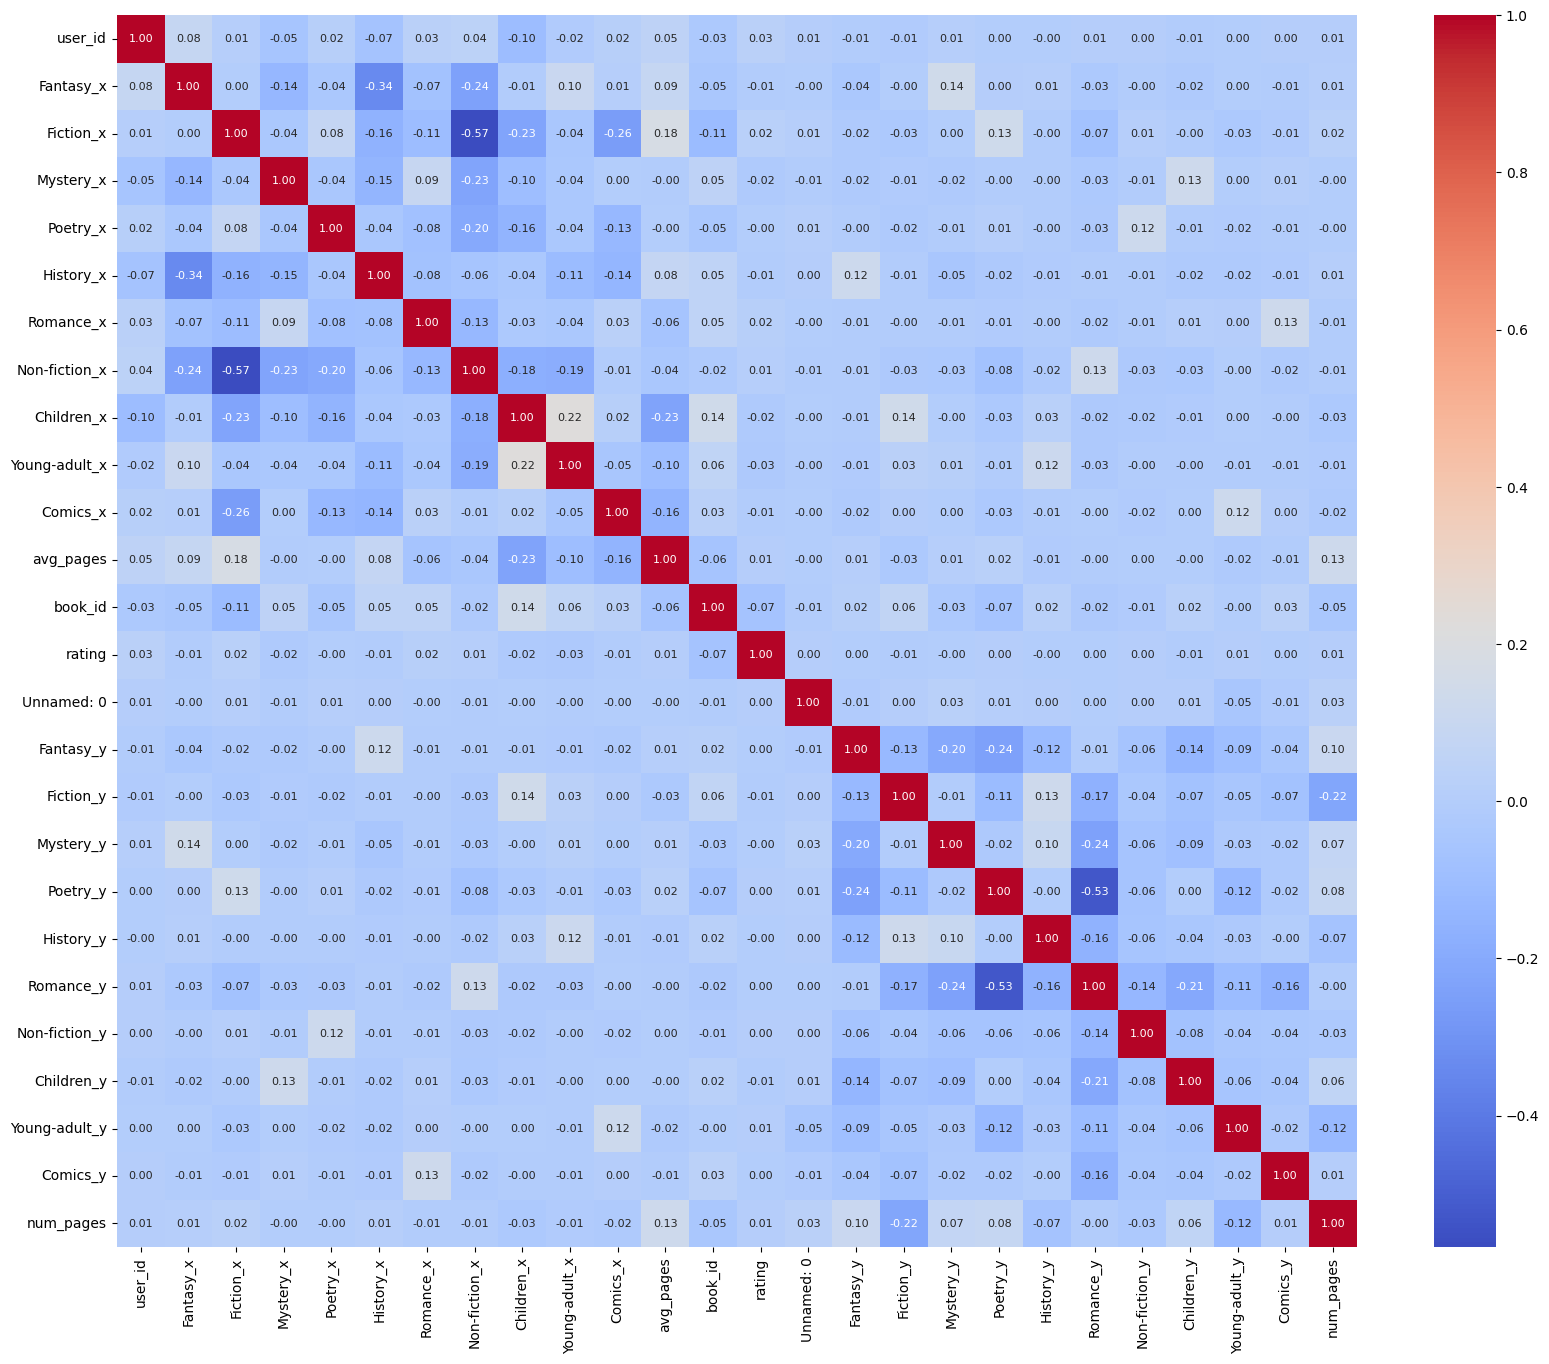

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ajustar el tamaño de la figura a algo más grande
plt.figure(figsize=(20, 16))  # Tamaño más grande para mejor visualización

# Calcular la matriz de correlación
correlation_matrix = final_dataset.corr()

# Crear el mapa de calor
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', annot_kws={"size":8})

# Ajustar el tamaño de la fuente de las anotaciones si es necesario
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Mostrar el gráfico
plt.show()


In [14]:
final_dataset

,user_id,Fantasy_x,Fiction_x,Mystery_x,Poetry_x,History_x,Romance_x,Non-fiction_x,Children_x,Young-adult_x,...,Fiction_y,Mystery_y,Poetry_y,History_y,Romance_y,Non-fiction_y,Children_y,Young-adult_y,Comics_y,num_pages
0,70551,0.093,0.251,0.094,0.013,0.118,0.040,0.259,0.077,0.031,...,0.615,0.000,0.000,0.077,0.269,0.038,0.0,0.0,0.000,64.0
1,356883,0.057,0.314,0.049,0.056,0.144,0.033,0.273,0.031,0.024,...,0.615,0.000,0.000,0.077,0.269,0.038,0.0,0.0,0.000,64.0
2,70551,0.093,0.251,0.094,0.013,0.118,0.040,0.259,0.077,0.031,...,0.017,0.125,0.783,0.075,0.000,0.000,0.0,0.0,0.000,NaN
3,72275,0.063,0.243,0.079,0.044,0.158,0.068,0.244,0.058,0.023,...,0.017,0.125,0.783,0.075,0.000,0.000,0.0,0.0,0.000,NaN
4,91312,0.069,0.343,0.059,0.036,0.146,0.038,0.223,0.048,0.021,...,0.017,0.125,0.783,0.075,0.000,0.000,0.0,0.0,0.000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74411,358254,0.076,0.371,0.043,0.088,0.161,0.011,0.162,0.074,0.014,...,0.000,0.000,1.000,0.000,0.000,0.000,0.0,0.0,0.000,NaN
74412,358254,0.076,0.371,0.043,0.088,0.161,0.011,0.162,0.074,0.014,...,0.000,0.000,0.632,0.000,0.000,0.000,0.0,0.0,0.041,336.0
74413,639898,0.004,0.238,0.000,0.023,0.233,0.033,0.397,0.000,0.000,...,0.000,0.000,0.000,0.000,1.000,0.000,0.0,0.0,0.000,NaN
74414,639898,0.004,0.238,0.000,0.023,0.233,0.033,0.397,0.000,0.000,...,0.000,0.000,0.000,0.000,0.438,0.062,0.0,0.0,0.000,384.0


In [21]:
final_dataset.drop(columns=["num_pages","Comics_y", "Romance_y", "History_y","Poetry_y","Mystery_y","Fantasy_y","Non-fiction_y","Poetry_x"], inplace=True)

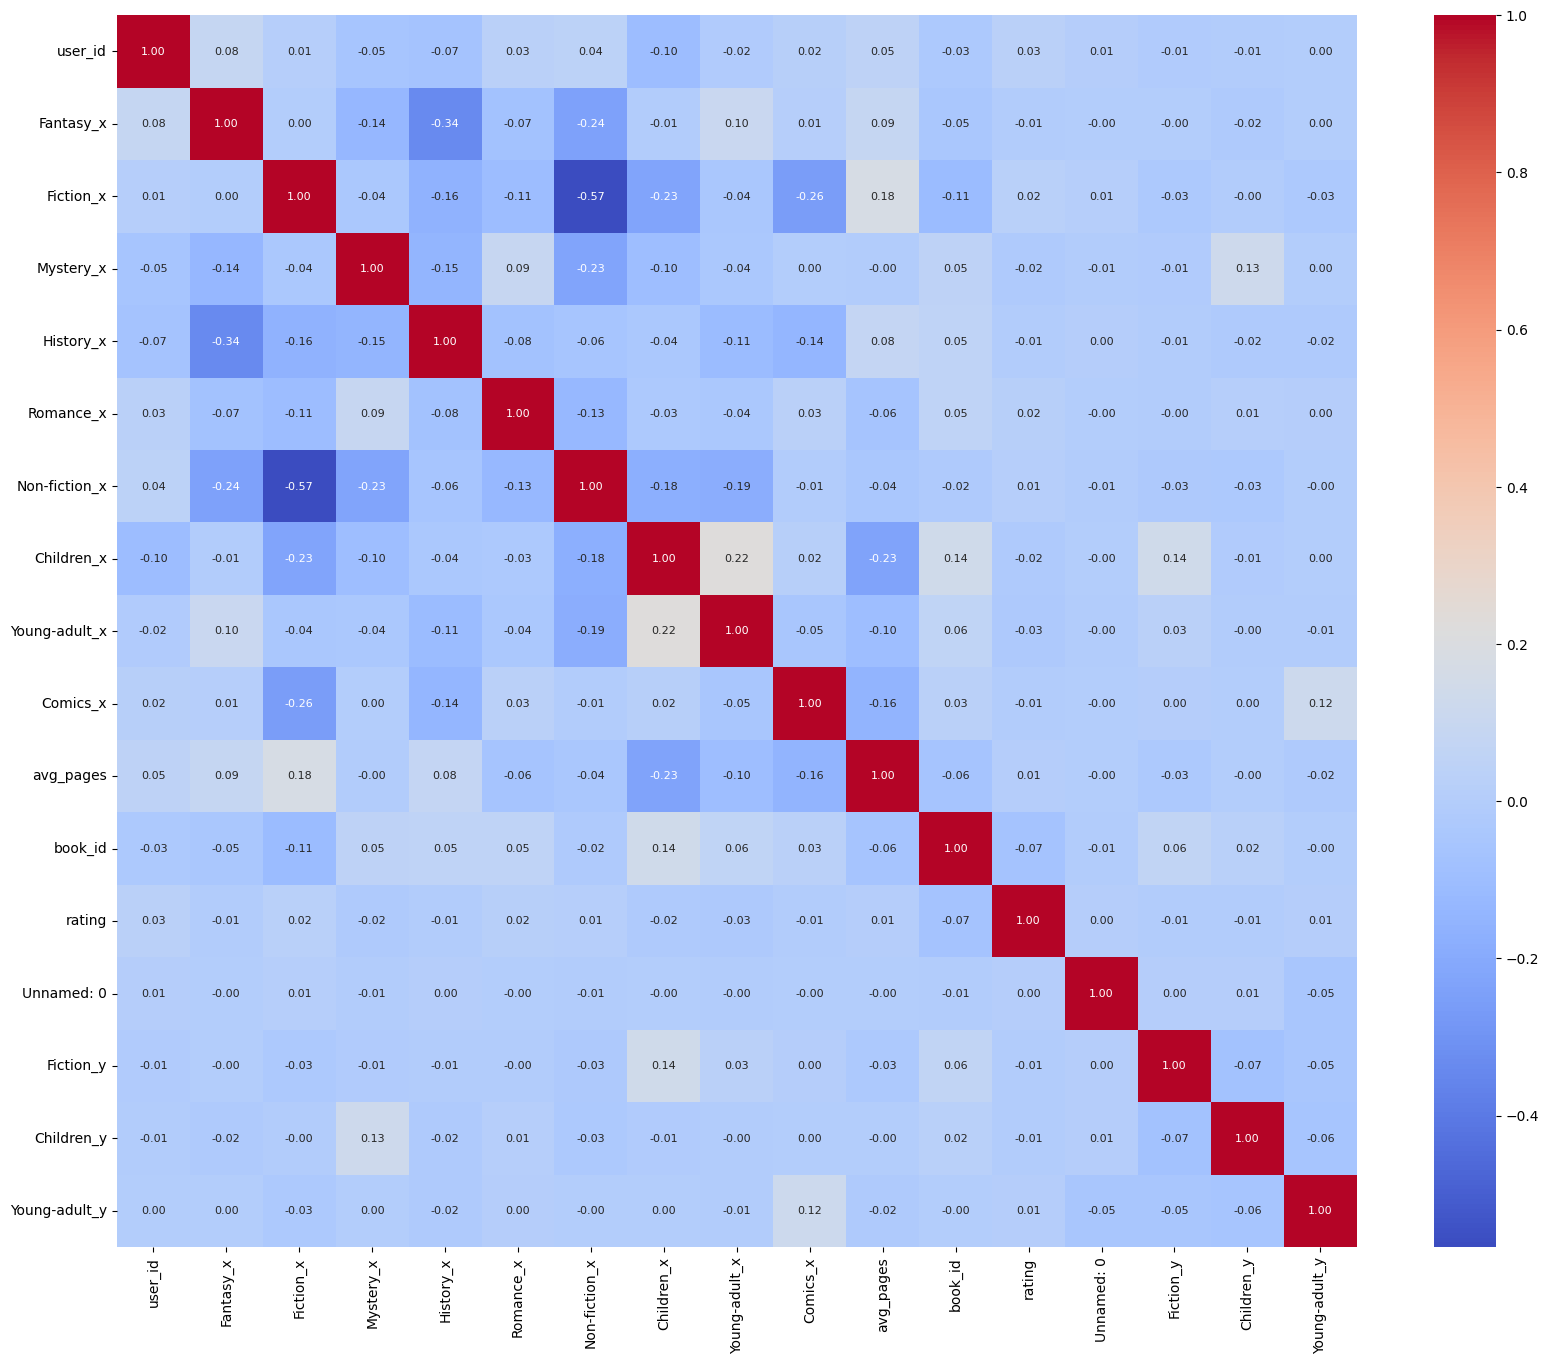

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ajustar el tamaño de la figura a algo más grande
plt.figure(figsize=(20, 16))  # Tamaño más grande para mejor visualización

# Calcular la matriz de correlación
correlation_matrix = final_dataset.corr()

# Crear el mapa de calor
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', annot_kws={"size":8})

# Ajustar el tamaño de la fuente de las anotaciones si es necesario
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Mostrar el gráfico
plt.show()


In [ ]:
final_dataset.drop(columns=["num_pages","Comics_y", "Romance_y", "History_y","Poetry_y","Mystery_y","Fantasy_y","Non-fiction_y"], inplace=True)

In [24]:
final_dataset

,user_id,Fantasy_x,Fiction_x,Mystery_x,History_x,Romance_x,Non-fiction_x,Children_x,Young-adult_x,Comics_x,avg_pages,book_id,rating,Unnamed: 0,Fiction_y,Children_y,Young-adult_y
0,70551,0.093,0.251,0.094,0.118,0.040,0.259,0.077,0.031,0.025,244.125000,3884,4,70958,0.615,0.0,0.0
1,356883,0.057,0.314,0.049,0.144,0.033,0.273,0.031,0.024,0.018,310.908654,3884,1,70958,0.615,0.0,0.0
2,70551,0.093,0.251,0.094,0.118,0.040,0.259,0.077,0.031,0.025,244.125000,50876,5,146367,0.017,0.0,0.0
3,72275,0.063,0.243,0.079,0.158,0.068,0.244,0.058,0.023,0.021,313.388462,50876,2,146367,0.017,0.0,0.0
4,91312,0.069,0.343,0.059,0.146,0.038,0.223,0.048,0.021,0.018,281.014925,50876,4,146367,0.017,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74411,358254,0.076,0.371,0.043,0.161,0.011,0.162,0.074,0.014,0.000,299.321429,105825,4,30883,0.000,0.0,0.0
74412,358254,0.076,0.371,0.043,0.161,0.011,0.162,0.074,0.014,0.000,299.321429,85987,0,292274,0.000,0.0,0.0
74413,639898,0.004,0.238,0.000,0.233,0.033,0.397,0.000,0.000,0.071,366.615385,1523569,5,351099,0.000,0.0,0.0
74414,639898,0.004,0.238,0.000,0.233,0.033,0.397,0.000,0.000,0.071,366.615385,345847,2,291449,0.000,0.0,0.0


#### Eliminar NAs

In [14]:
notnas = final_dataset.dropna()

In [15]:
notnas

,user_id,Fantasy_x,Fiction_x,Mystery_x,Poetry_x,History_x,Romance_x,Non-fiction_x,Children_x,Young-adult_x,...,Fiction_y,Mystery_y,Poetry_y,History_y,Romance_y,Non-fiction_y,Children_y,Young-adult_y,Comics_y,num_pages
0,70551,0.093,0.251,0.094,0.013,0.118,0.040,0.259,0.077,0.031,...,0.615,0.000,0.000,0.077,0.269,0.038,0.000,0.000,0.000,64.0
1,356883,0.057,0.314,0.049,0.056,0.144,0.033,0.273,0.031,0.024,...,0.615,0.000,0.000,0.077,0.269,0.038,0.000,0.000,0.000,64.0
8,70551,0.093,0.251,0.094,0.013,0.118,0.040,0.259,0.077,0.031,...,0.000,0.000,0.000,0.000,0.567,0.000,0.000,0.000,0.000,287.0
9,381034,0.032,0.314,0.106,0.039,0.133,0.036,0.253,0.040,0.005,...,0.000,0.000,0.000,0.000,0.567,0.000,0.000,0.000,0.000,287.0
10,70551,0.093,0.251,0.094,0.013,0.118,0.040,0.259,0.077,0.031,...,0.000,0.074,0.661,0.000,0.000,0.000,0.228,0.000,0.000,121.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74408,539048,0.057,0.149,0.042,0.047,0.105,0.003,0.504,0.072,0.021,...,0.069,0.207,0.345,0.172,0.000,0.000,0.207,0.000,0.000,112.0
74409,539048,0.057,0.149,0.042,0.047,0.105,0.003,0.504,0.072,0.021,...,0.000,0.000,0.000,0.000,0.353,0.000,0.000,0.003,0.000,372.0
74412,358254,0.076,0.371,0.043,0.088,0.161,0.011,0.162,0.074,0.014,...,0.000,0.000,0.632,0.000,0.000,0.000,0.000,0.000,0.041,336.0
74414,639898,0.004,0.238,0.000,0.023,0.233,0.033,0.397,0.000,0.000,...,0.000,0.000,0.000,0.000,0.438,0.062,0.000,0.000,0.000,384.0


### Decision tree

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score,classification_report
import matplotlib.pyplot as plt

In [39]:
X = notnas.drop(['rating','user_id'],axis=True)
X['book_id'] = X['book_id'].astype('category')
y = notnas['rating']

In [40]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 60136 entries, 0 to 74415
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   Fantasy_x      60136 non-null  float64 
 1   Fiction_x      60136 non-null  float64 
 2   Mystery_x      60136 non-null  float64 
 3   Poetry_x       60136 non-null  float64 
 4   History_x      60136 non-null  float64 
 5   Romance_x      60136 non-null  float64 
 6   Non-fiction_x  60136 non-null  float64 
 7   Children_x     60136 non-null  float64 
 8   Young-adult_x  60136 non-null  float64 
 9   Comics_x       60136 non-null  float64 
 10  avg_pages      60136 non-null  float64 
 11  book_id        60136 non-null  category
 12  Unnamed: 0     60136 non-null  int64   
 13  Fantasy_y      60136 non-null  float64 
 14  Fiction_y      60136 non-null  float64 
 15  Mystery_y      60136 non-null  float64 
 16  Poetry_y       60136 non-null  float64 
 17  History_y      60136 non-null  

In [19]:
corr = X.corr()
corr.style.background_gradient(cmap='RdYlBu').set_precision(4)

C:\Users\llumf\AppData\Local\Temp\ipykernel_9012\3915399208.py:2: FutureWarning: this method is deprecated in favour of `Styler.format(precision=..)`
  corr.style.background_gradient(cmap='RdYlBu').set_precision(4)


,Fantasy_x,Fiction_x,Mystery_x,Poetry_x,History_x,Romance_x,Non-fiction_x,Children_x,Young-adult_x,Comics_x,avg_pages,Unnamed: 0,Fantasy_y,Fiction_y,Mystery_y,Poetry_y,History_y,Romance_y,Non-fiction_y,Children_y,Young-adult_y,Comics_y,num_pages
Fantasy_x,1.0000,-0.0022,-0.1409,-0.0332,-0.3359,-0.0706,-0.2379,-0.0079,0.1041,0.0119,0.0808,-0.0028,-0.0399,0.0009,0.1419,0.0004,0.0125,-0.0321,-0.0038,-0.0219,0.0040,-0.0035,0.0102
Fiction_x,-0.0022,1.0000,-0.0335,0.0821,-0.1643,-0.1104,-0.5667,-0.2255,-0.0460,-0.2621,0.1802,0.0071,-0.0254,-0.0336,0.0010,0.1361,-0.0076,-0.0736,0.0143,0.0015,-0.0314,-0.0172,0.0228
Mystery_x,-0.1409,-0.0335,1.0000,-0.0473,-0.1478,0.0917,-0.2310,-0.0971,-0.0358,0.0001,-0.0020,-0.0047,-0.0172,-0.0135,-0.0203,-0.0042,-0.0031,-0.0275,-0.0071,0.1276,-0.0026,0.0063,-0.0003
Poetry_x,-0.0332,0.0821,-0.0473,1.0000,-0.0381,-0.0800,-0.2093,-0.1585,-0.0403,-0.1265,-0.0014,0.0101,-0.0054,-0.0248,-0.0058,0.0128,-0.0054,-0.0262,0.1260,-0.0038,-0.0167,-0.0142,-0.0002
History_x,-0.3359,-0.1643,-0.1478,-0.0381,1.0000,-0.0821,-0.0565,-0.0337,-0.1092,-0.1443,0.0760,0.0067,0.1265,-0.0067,-0.0479,-0.0227,-0.0122,-0.0088,-0.0043,-0.0211,-0.0189,-0.0116,0.0096
Romance_x,-0.0706,-0.1104,0.0917,-0.0800,-0.0821,1.0000,-0.1284,-0.0312,-0.0371,0.0297,-0.0645,-0.0025,-0.0076,-0.0037,-0.0100,-0.0151,-0.0056,-0.0198,-0.0076,0.0213,0.0036,0.1262,-0.0082
Non-fiction_x,-0.2379,-0.5667,-0.2310,-0.2093,-0.0565,-0.1284,1.0000,-0.1797,-0.1854,-0.0080,-0.0431,-0.0080,-0.0078,-0.0236,-0.0341,-0.0767,-0.0207,0.1311,-0.0249,-0.0330,0.0010,-0.0137,-0.0055
Children_x,-0.0079,-0.2255,-0.0971,-0.1585,-0.0337,-0.0312,-0.1797,1.0000,0.2237,0.0141,-0.2338,0.0006,-0.0012,0.1399,-0.0023,-0.0308,0.0268,-0.0243,-0.0272,-0.0149,-0.0021,-0.0023,-0.0295
Young-adult_x,0.1041,-0.0460,-0.0358,-0.0403,-0.1092,-0.0371,-0.1854,0.2237,1.0000,-0.0520,-0.0995,-0.0053,-0.0122,0.0320,0.0170,-0.0050,0.1197,-0.0264,-0.0114,-0.0054,-0.0078,-0.0033,-0.0126
Comics_x,0.0119,-0.2621,0.0001,-0.1265,-0.1443,0.0297,-0.0080,0.0141,-0.0520,1.0000,-0.1585,-0.0008,-0.0173,0.0040,0.0019,-0.0403,-0.0073,0.0006,-0.0185,-0.0021,0.1241,0.0070,-0.0200


In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Asumiendo que X e y ya están definidos:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Crear y entrenar el modelo de Random Forest
model = RandomForestClassifier(
    n_estimators=200,  # Número de árboles en el bosque.
    criterion='entropy',  # Puedes probar 'entropy' para ver si mejora el rendimiento.
    max_depth=None,  # Profundidad máxima del árbol.
    min_samples_split=2,  # Número mínimo de muestras requeridas para dividir un nodo.
    min_samples_leaf=1,  # Número mínimo de muestras requeridas para ser una hoja.
    max_features='sqrt',  # Establecer explícitamente a 'sqrt' según la advertencia.
    max_leaf_nodes=None,  # Número máximo de nodos hoja.
    bootstrap=True,  # Utilizar muestras de bootstrap para construir árboles.
    random_state=42,
    n_jobs=-1,  # Número de trabajos en paralelo.
    oob_score=True  # Usar muestras fuera de la bolsa para estimar la precisión general.
)

model.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
y_pred = model.predict(X_test)

# Calcular la precisión del modelo
accuracy = accuracy_score(y_test, y_pred)
print(f'Precisión del modelo: {accuracy:.2f}')

# También podemos ver la importancia de las características
feature_importances = model.feature_importances_


Precisión del modelo: 0.45


In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score

# Asumiendo que X e y ya están definidos:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Definir un diccionario con los parámetros que quieres probar
param_grid = {
    'n_estimators': [100, 200, 300],  # Probar con 100, 200 y 300 árboles
    'criterion': ['gini', 'entropy'],  # Funciones para medir la calidad de una división
    'max_depth': [None, 10, 20],  # Profundidades máximas del árbol
}

# Crear el modelo de Grid Search con un RandomForestClassifier
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,  # Número de pliegues en la validación cruzada
    n_jobs=-1,  # Usar todos los procesadores disponibles
    verbose=2  # Mostrar más información durante el entrenamiento
)

# Ajustar el modelo Grid Search al conjunto de entrenamiento
grid_search.fit(X_train, y_train)

# Obtener los mejores parámetros
best_params = grid_search.best_params_
print(f'Mejores parámetros: {best_params}')

# Crear y entrenar el modelo con los mejores parámetros
best_model = grid_search.best_estimator_

# Realizar predicciones en el conjunto de prueba con el mejor modelo
y_pred = best_model.predict(X_test)

# Calcular la precisión del mejor modelo
accuracy = accuracy_score(y_test, y_pred)
print(f'Precisión del mejor modelo: {accuracy:.2f}')

## OUTPUT DE UN ALTRE NOTEBOOK:
"""Fitting 5 folds for each of 18 candidates, totalling 90 fits
Mejores parámetros: {'criterion': 'gini', 'max_depth': 20, 'n_estimators': 300}
Precisión del mejor modelo: 0.46"""

Fitting 5 folds for each of 18 candidates, totalling 90 fits


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Crear y entrenar el modelo de árbol de decisiones
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
y_pred = model.predict(X_test)

# Calcular la precisión del modelo
accuracy = accuracy_score(y_test, y_pred)
print(f'Precisión del modelo: {accuracy:.2f}')

Precisión del modelo: 0.40


C:\Users\llumf\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\llumf\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\llumf\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarni

              precision    recall  f1-score   support

           1       0.00      0.00      0.00         0
           2       0.01      0.22      0.02        23
           3       0.19      0.45      0.26      1054
           4       0.58      0.42      0.49      5638
           5       0.59      0.49      0.53      4548

    accuracy                           0.45     11263
   macro avg       0.27      0.32      0.26     11263
weighted avg       0.54      0.45      0.48     11263



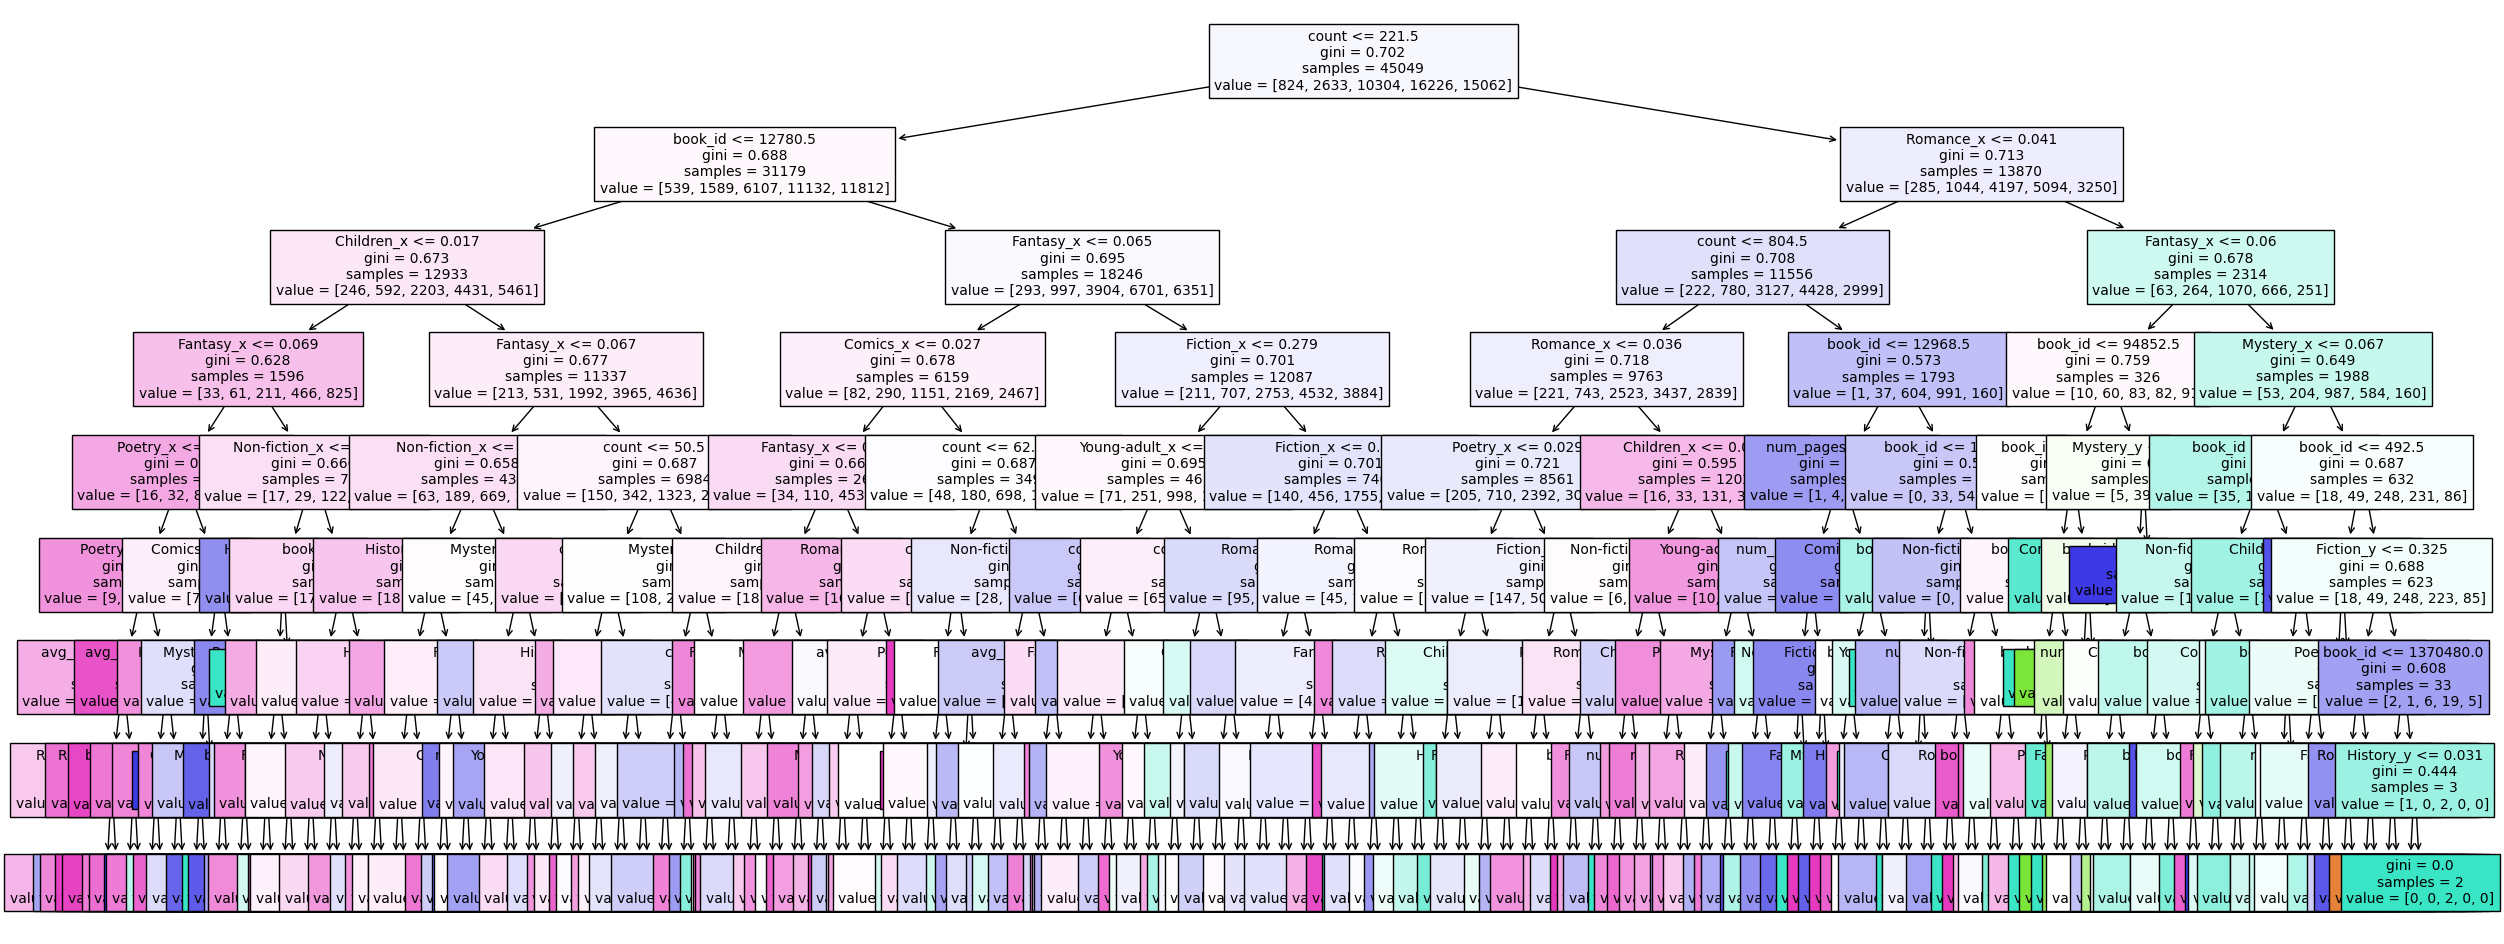

In [ ]:
columnes = X.columns
model = DecisionTreeClassifier(max_depth=8, random_state=10)
model = model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred = y_pred
y_testid = y_test.to_numpy()
print(classification_report(y_pred,y_test))

plt.figure(figsize=(30,12))  # set plot size (denoted in inches)
plot_tree(model, fontsize=10, feature_names = columnes, filled=True)
plt.show()

### MLP

In [42]:
X.columns

Index(['Fantasy_x', 'Fiction_x', 'Mystery_x', 'Poetry_x', 'History_x',
       'Romance_x', 'Non-fiction_x', 'Children_x', 'Young-adult_x', 'Comics_x',
       'avg_pages', 'book_id', 'Unnamed: 0', 'Fantasy_y', 'Fiction_y',
       'Mystery_y', 'Poetry_y', 'History_y', 'Romance_y', 'Non-fiction_y',
       'Children_y', 'Young-adult_y', 'Comics_y', 'num_pages', 'Fantasy'],
      dtype='object')

In [46]:
genres = ['Fantasy', 'Fiction', 'Mystery', 'Poetry', 'History',
          'Romance', 'Non-fiction', 'Children', 'Young-adult', 'Comics']
for gen in genres:
    X[gen] = X[f'{gen}_x']-X[f'{gen}_y']
    X.drop([f'{gen}_x',f'{gen}_y'],axis=1,inplace=True)
X['pagines'] = X['avg_pages']-X['num_pages']

In [48]:
X.drop('Unnamed: 0',axis=1,inplace=True)

In [49]:
X

,avg_pages,book_id,num_pages,Fantasy,Fiction,Mystery,Poetry,History,Romance,Non-fiction,Children,Young-adult,Comics,pagines
0,244.125000,3884,64.0,0.093,-0.364,0.094,0.013,0.041,-0.229,0.221,0.077,0.031,0.025,180.125000
1,310.908654,3884,64.0,0.057,-0.301,0.049,0.056,0.067,-0.236,0.235,0.031,0.024,0.018,246.908654
8,244.125000,75731,287.0,-0.340,0.251,0.094,0.013,0.118,-0.527,0.259,0.077,0.031,0.025,-42.875000
9,339.203704,75731,287.0,-0.401,0.314,0.106,0.039,0.133,-0.531,0.253,0.040,0.005,0.042,52.203704
10,244.125000,12948,121.0,0.056,0.251,0.020,-0.648,0.118,0.040,0.259,-0.151,0.031,0.025,123.125000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74408,352.833333,47641,112.0,0.057,0.080,-0.165,-0.298,-0.067,0.003,0.504,-0.135,0.021,0.001,240.833333
74409,352.833333,47632,372.0,-0.587,0.149,0.042,0.047,0.105,-0.350,0.504,0.072,0.018,0.001,-19.166667
74412,299.321429,85987,336.0,-0.250,0.371,0.043,-0.544,0.161,0.011,0.162,0.074,0.014,-0.041,-36.678571
74414,366.615385,345847,384.0,-0.496,0.238,0.000,0.023,0.233,-0.405,0.335,0.000,0.000,0.071,-17.384615


In [19]:
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, GlobalMaxPooling1D, Conv1D, GlobalAveragePooling1D

In [27]:
from sklearn.decomposition import PCA
import numpy as np
pca = PCA(n_components=0.90, svd_solver='full')
X_pca = pca.fit_transform(X)

# Determinar la nova dimensionalitat que sigui una potència de 2 més propera
dim = 2**int(np.ceil(np.log2(pca.n_components_)))
pca = PCA(n_components=dim)
X_pca = pca.fit_transform(X)

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [51]:
from keras.utils import to_categorical

num_classes = 6

y_train_one_hot = to_categorical(y_train, num_classes=num_classes)
y_test_one_hot = to_categorical(y_test, num_classes=num_classes)

model = Sequential()
model.add(Dense(128,activation='relu'))
model.add(Dense(128,activation='relu'))
model.add(Dense(num_classes,activation = 'softmax'))

# Compile the model
model.compile(optimizer='adamax', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
batch_size = 256
epochs = 10

model.fit(X_train, y_train_one_hot, batch_size=batch_size, epochs=epochs)

# Evaluate the model on the test set

loss, accuracy = model.evaluate(X_test, y_test_one_hot, batch_size=batch_size)
print(f"Test accuracy: {accuracy:.2f}")

Epoch 1/10
188/188 [==============================] - 1s 2ms/step - loss: 642.4183 - accuracy: 0.2637
Epoch 2/10
188/188 [==============================] - 0s 2ms/step - loss: 453.1314 - accuracy: 0.2724
Epoch 3/10
188/188 [==============================] - 0s 2ms/step - loss: 508.3568 - accuracy: 0.2638
Epoch 4/10
188/188 [==============================] - 0s 2ms/step - loss: 378.7693 - accuracy: 0.2683
Epoch 5/10
188/188 [==============================] - 0s 2ms/step - loss: 353.8218 - accuracy: 0.2747
Epoch 6/10
188/188 [==============================] - 0s 2ms/step - loss: 390.1304 - accuracy: 0.2682
Epoch 7/10
188/188 [==============================] - 0s 2ms/step - loss: 391.4257 - accuracy: 0.2704
Epoch 8/10
188/188 [==============================] - 0s 2ms/step - loss: 371.7673 - accuracy: 0.2679
Epoch 9/10
188/188 [==============================] - 0s 2ms/step - loss: 363.3769 - accuracy: 0.2749
Epoch 10/10
47/47 [==============================] - 0s 2ms/step - loss: 434.1393 